In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8

STEP 1. Parameter Sweep
Number of Parameters : 110


STEP 2. Target 설정
Target : -1.0


STEP 3. Prediction 계산
Prediction 계산 완료


STEP 4. Loss 계산
Loss 계산 완료


STEP 5. 최소 Loss 탐색
Best Theta      : 3.112771
Prediction      : -0.999585
Loss            : 0.00000017


STEP 6. 일부 결과
     Theta     Prediction         Target           Loss
-------------------------------------------------------
    0.0000         1.0000        -1.0000       4.000000
    0.6917         0.7701        -1.0000       3.133416
    1.3835         0.1862        -1.0000       1.407186
    2.0752        -0.4833        -1.0000       0.267012
    2.7669        -0.9306        -1.0000       0.004813
    3.4586        -0.9502        -1.0000       0.002484
    4.1504        -0.5329        -1.0000       0.218179
    4.8421         0.1293        -1.0000       1.275399
    5.5338         0.7321        -1.0000       3.000232
    6.2832         1.0000        -1.0000       4.000000


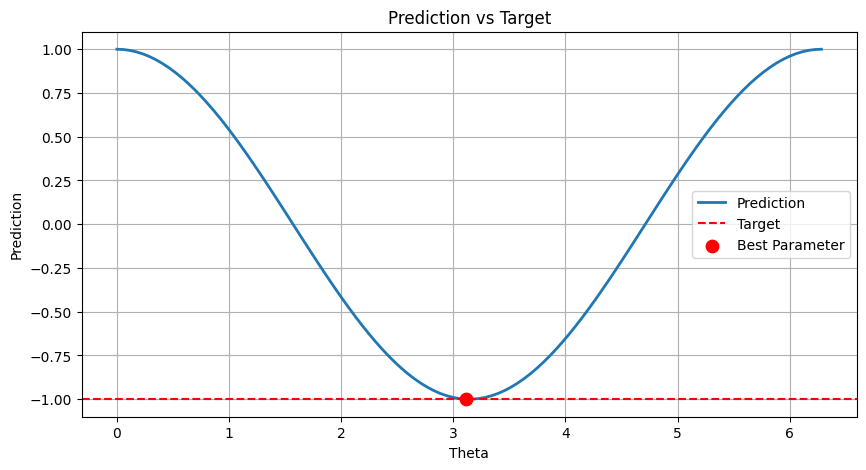

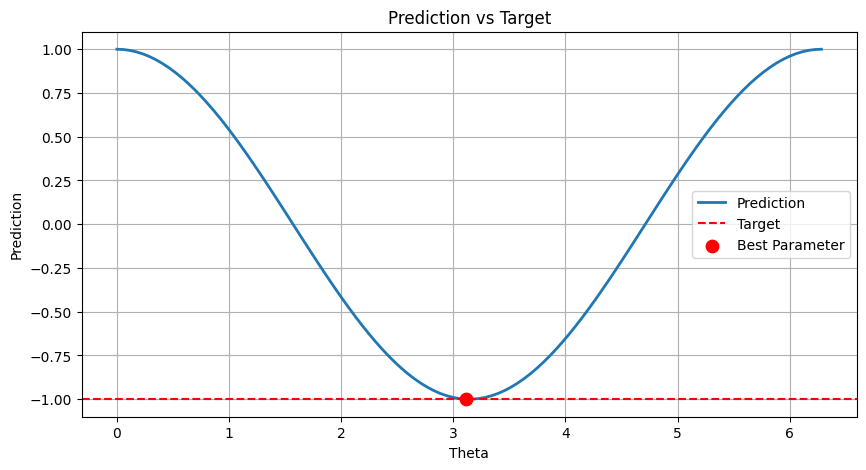

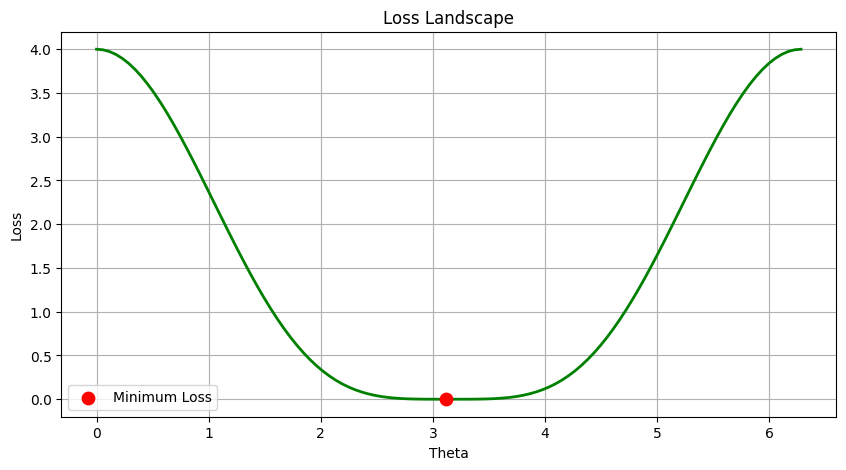

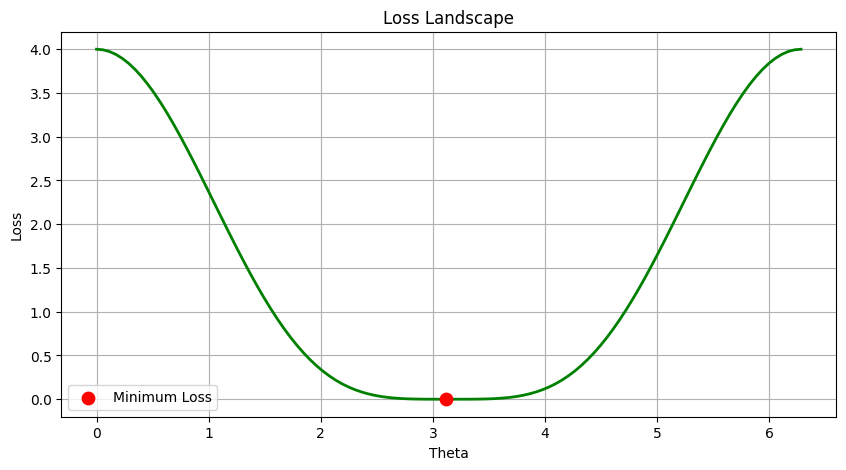

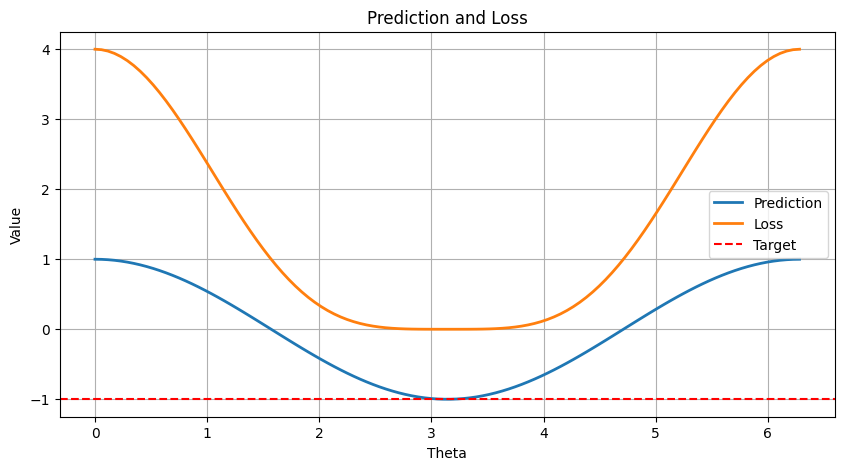

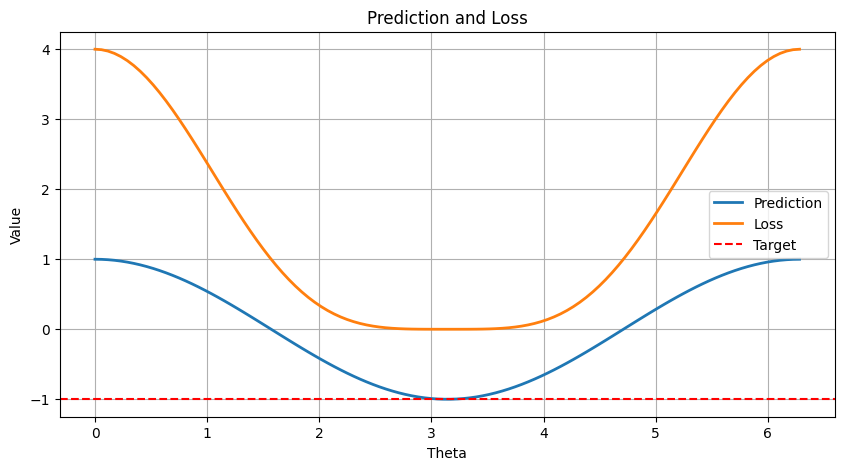



STEP 10. Summary
Target              : -1.0
Best Parameter θ    : 3.112771
Prediction          : -0.999585
Minimum Loss        : 0.00000017

Loss Curve 생성 완료


In [4]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import SparsePauliOp

# ============================================================
# STEP 1. Parameter 생성
# ============================================================

print("=" * 80)
print("STEP 1. Parameter Sweep")
print("=" * 80)

theta_values = np.linspace(
    0,
    2 * np.pi,
    110
)

print(f"Number of Parameters : {len(theta_values)}")

# ============================================================
# STEP 2. Target 설정
# ============================================================

print("\n")
print("=" * 80)
print("STEP 2. Target 설정")
print("=" * 80)

target = -1.0

print(f"Target : {target}")

# ============================================================
# STEP 3. Prediction 계산
# ============================================================

print("\n")
print("=" * 80)
print("STEP 3. Prediction 계산")
print("=" * 80)

observable = SparsePauliOp.from_list(
    [("Z", 1)]
)

predictions = []

for theta in theta_values:
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    state = Statevector.from_instruction(qc)
    prediction = np.real(
        state.expectation_value(observable)
    )
    predictions.append(prediction)

predictions = np.array(predictions)

print("Prediction 계산 완료")

# ============================================================
# STEP 4. Loss 계산
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4. Loss 계산")
print("=" * 80)

losses = (
    predictions - target
) ** 2

print("Loss 계산 완료")

# ============================================================
# STEP 5. 최소 Loss 찾기
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5. 최소 Loss 탐색")
print("=" * 80)

best_index = np.argmin(losses)

best_theta = theta_values[best_index]

best_prediction = predictions[best_index]

best_loss = losses[best_index]

print(f"Best Theta      : {best_theta:.6f}")
print(f"Prediction      : {best_prediction:.6f}")
print(f"Loss            : {best_loss:.8f}")

# ============================================================
# STEP 6. 결과 테이블 출력
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6. 일부 결과")
print("=" * 80)

print(
    f"{'Theta':>10}"
    f"{'Prediction':>15}"
    f"{'Target':>15}"
    f"{'Loss':>15}"
)

print("-" * 55)

sample_index = np.linspace(
    0,
    len(theta_values) - 1,
    10,
    dtype=int
)

for i in sample_index:
    print(
        f"{theta_values[i]:10.4f}"
        f"{predictions[i]:15.4f}"
        f"{target:15.4f}"
        f"{losses[i]:15.6f}"
    )

# ============================================================
# STEP 7. Prediction Curve
# ============================================================

fig1 = plt.figure(figsize=(10, 5))

plt.plot(
    theta_values,
    predictions,
    linewidth=2,
    label="Prediction"
)

plt.axhline(
    target,
    linestyle="--",
    color="red",
    label="Target"
)

plt.scatter(
    best_theta,
    best_prediction,
    color="red",
    s=80,
    zorder=5,
    label="Best Parameter"
)

plt.xlabel("Theta")
plt.ylabel("Prediction")
plt.title("Prediction vs Target")
plt.grid(True)
plt.legend()
display(fig1)
plt.show()

# ============================================================
# STEP 8. Loss Curve (코랩 맞춤 display 적용)
# ============================================================

fig2 = plt.figure(figsize=(10, 5))

plt.plot(
    theta_values,
    losses,
    linewidth=2,
    color="green"
)

plt.scatter(
    best_theta,
    best_loss,
    color="red",
    s=80,
    zorder=5,
    label="Minimum Loss"
)

plt.xlabel("Theta")
plt.ylabel("Loss")
plt.title("Loss Landscape")
plt.grid(True)
plt.legend()
display(fig2)
plt.show()

# ============================================================
# STEP 9. Prediction과 Loss 동시 비교
# ============================================================

fig3 = plt.figure(figsize=(10, 5))

plt.plot(
    theta_values,
    predictions,
    label="Prediction",
    linewidth=2
)

plt.plot(
    theta_values,
    losses,
    label="Loss",
    linewidth=2
)

plt.axhline(
    target,
    linestyle="--",
    color="red",
    label="Target"
)

plt.xlabel("Theta")
plt.ylabel("Value")
plt.title("Prediction and Loss")
plt.grid(True)
plt.legend()
display(fig3)
plt.show()

# ============================================================
# STEP 10. 결과 요약
# ============================================================

print("\n")
print("=" * 80)
print("STEP 10. Summary")
print("=" * 80)

print(f"Target              : {target}")
print(f"Best Parameter θ    : {best_theta:.6f}")
print(f"Prediction          : {best_prediction:.6f}")
print(f"Minimum Loss        : {best_loss:.8f}")

print("\nLoss Curve 생성 완료")